Flight Price Prediction Using Machine Learning

Step 1: Problem Statement

Flight ticket prices are highly dynamic and can change depending on various factors such as airline, journey date, departure time, arrival time, flight duration, source, destination, and number of stops.

Predicting flight ticket prices accurately can help customers plan their journeys and make better booking decisions. It can also help airlines understand pricing patterns and maintain competitive ticket prices.

This project aims to analyze flight fare data and develop Machine Learning models to predict flight ticket prices based on various travel-related features.


Step 2: Project Objective

- To perform Exploratory Data Analysis (EDA) on the flight fare dataset.
- To understand the relationship between different flight features and ticket prices.
- To identify and handle missing values, duplicate records, and inconsistent data.
- To perform data preprocessing and feature engineering.
- To build multiple Machine Learning regression models for flight price prediction.
- To evaluate model performance using suitable evaluation metrics.
- To compare different models and identify the best-performing model.
- To document the challenges faced and the techniques used to overcome them.


Step 3: Importing Required Libraries

In [1]:
# Importing Required Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


Step 4: Loading the Dataset

In [2]:
# Checking files in the current directory

print(os.listdir())

['.ipynb_checkpoints', 'Flight_Price_Prediction.ipynb']


In [3]:
print(os.getcwd())

C:\Users\ADMIN\Flight Fare Prediction


In [4]:
os.chdir(r"E:\Flight Fare Prediction")
print(os.getcwd())

E:\Flight Fare Prediction


In [5]:
print(os.listdir())

['Flight_Fare.xlsx']


Step 5: Load the Dataset

In [6]:
# Loading the Flight Fare dataset

df = pd.read_excel("Flight_Fare.xlsx")
print("Dataset loaded successfully!")

Dataset loaded successfully!


Step 5.1: Display the first five records

In [7]:
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


Step 5.2: Check the dataset shape

In [8]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 10683
Number of Columns: 11


Step 6: Understanding the Dataset

Step 6.1: Check dataset information

In [9]:
# Dataset Information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


Step 6.2: Check dataset dimensions

In [10]:
# Dataset Dimensions

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 10683
Total Columns: 11


Step 6.3: Display column names

In [11]:
# Displaying Column Names

print("Dataset Columns:")
print(df.columns.tolist())

Dataset Columns:
['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route', 'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops', 'Additional_Info', 'Price']


Step 6.4: Statistical summary

In [12]:
# Statistical Summary

df.describe(include='all')

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
count,10683,10683,10683,10683,10682,10683,10683,10683,10682,10683,10683.000000
unique,12,44,5,6,128,222,1343,368,5,10,NaN
top,Jet Airways,18/05/2019,Delhi,Cochin,DEL → BOM → COK,18:55,19:00,2h 50m,1 stop,No info,NaN
freq,3849,504,4537,4537,2376,233,423,550,5625,8345,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9087.064121
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4611.359167
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1759.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5277.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8372.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12373.000000


Step 6.5: Check first and last five records

In [13]:
# First Five Records
display(df.head())

# Last Five Records
display(df.tail())

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648
10682,Air India,9/05/2019,Delhi,Cochin,DEL → GOI → BOM → COK,10:55,19:15,8h 20m,2 stops,No info,11753


Step 7: Checking Missing Values

Step 7.1: Check missing values

In [14]:
# Checking Missing Values

df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

Step 7.2: Calculate missing value percentage

In [15]:
# Missing Value Percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_percentage

Airline            0.000000
Date_of_Journey    0.000000
Source             0.000000
Destination        0.000000
Route              0.009361
Dep_Time           0.000000
Arrival_Time       0.000000
Duration           0.000000
Total_Stops        0.009361
Additional_Info    0.000000
Price              0.000000
dtype: float64

Step 7.3: Visualize missing values

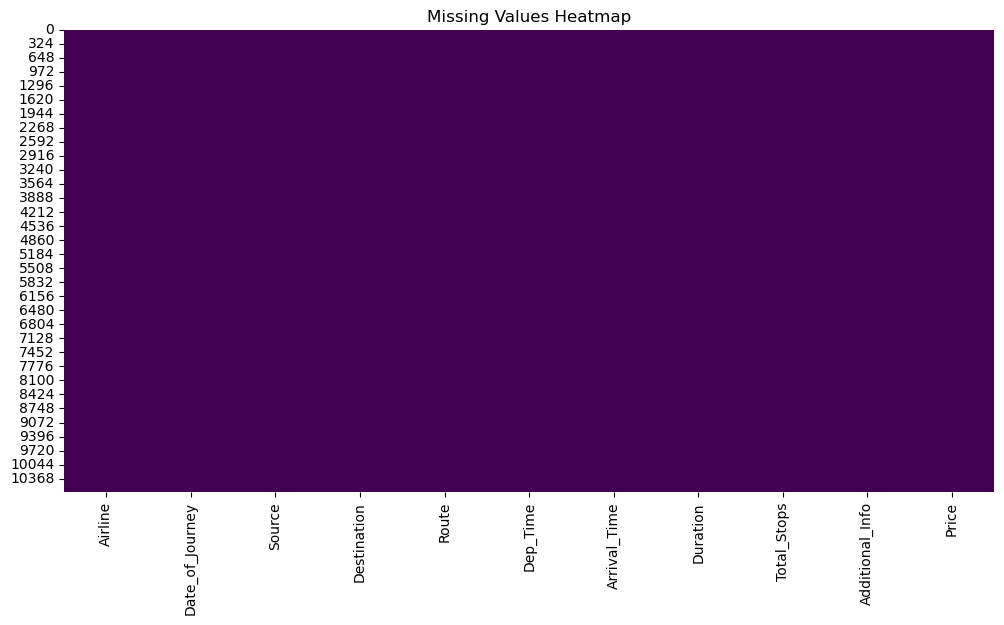

In [16]:
# Visualizing Missing Values

plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False, cmap='viridis')

plt.title("Missing Values Heatmap")
plt.show()

Step 7.4: Check duplicate records

In [17]:
# Checking Duplicate Records

print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 220


Step 8: Data Cleaning and Preprocessing

Step 8.1: Check column data types

In [18]:
# Checking Data Types

df.dtypes

Airline            object
Date_of_Journey    object
Source             object
Destination        object
Route              object
Dep_Time           object
Arrival_Time       object
Duration           object
Total_Stops        object
Additional_Info    object
Price               int64
dtype: object

Step 8.2: Check unique values in categorical columns

In [19]:
# Checking Unique Values

for col in df.select_dtypes(include='object').columns:
    print(f"\nColumn: {col}")
    print(df[col].unique()[:20])


Column: Airline
['IndiGo' 'Air India' 'Jet Airways' 'SpiceJet' 'Multiple carriers' 'GoAir'
 'Vistara' 'Air Asia' 'Vistara Premium economy' 'Jet Airways Business'
 'Multiple carriers Premium economy' 'Trujet']

Column: Date_of_Journey
['24/03/2019' '1/05/2019' '9/06/2019' '12/05/2019' '01/03/2019'
 '24/06/2019' '12/03/2019' '27/05/2019' '1/06/2019' '18/04/2019'
 '9/05/2019' '24/04/2019' '3/03/2019' '15/04/2019' '12/06/2019'
 '6/03/2019' '21/03/2019' '3/04/2019' '6/05/2019' '15/05/2019']

Column: Source
['Banglore' 'Kolkata' 'Delhi' 'Chennai' 'Mumbai']

Column: Destination
['New Delhi' 'Banglore' 'Cochin' 'Kolkata' 'Delhi' 'Hyderabad']

Column: Route
['BLR → DEL' 'CCU → IXR → BBI → BLR' 'DEL → LKO → BOM → COK'
 'CCU → NAG → BLR' 'BLR → NAG → DEL' 'CCU → BLR' 'BLR → BOM → DEL'
 'DEL → BOM → COK' 'DEL → BLR → COK' 'MAA → CCU' 'CCU → BOM → BLR'
 'DEL → AMD → BOM → COK' 'DEL → PNQ → COK' 'DEL → CCU → BOM → COK'
 'BLR → COK → DEL' 'DEL → IDR → BOM → COK' 'DEL → LKO → COK'
 'CCU → GAU → DEL →

Step 8.3: Check unique value counts

In [20]:
# Number of Unique Values in Each Column

df.nunique()

Airline              12
Date_of_Journey      44
Source                5
Destination           6
Route               128
Dep_Time            222
Arrival_Time       1343
Duration            368
Total_Stops           5
Additional_Info      10
Price              1870
dtype: int64

Step 8.4: Check duplicate records again

In [21]:
# Duplicate Records

print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 220


Step 8.5: Inspect numerical columns

In [22]:
# Numerical Column Summary

df.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


Step 9: Handling Duplicate Records

Step 9.1: Remove duplicates

In [23]:
# Removing Duplicate Records

print("Before Removing Duplicates:", df.shape)

df.drop_duplicates(inplace=True)

print("After Removing Duplicates:", df.shape)

print("Duplicate Records Remaining:", df.duplicated().sum())

Before Removing Duplicates: (10683, 11)
After Removing Duplicates: (10463, 11)
Duplicate Records Remaining: 0


Step 9.2: Reset the index

In [24]:
# Resetting Dataset Index

df.reset_index(drop=True, inplace=True)

print("Dataset index reset successfully!")

Dataset index reset successfully!


Step 10: Handling Missing Values

Step 10.1: Check missing values

In [25]:
# Checking Missing Values

print(df.isnull().sum())

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64


Step 10.2: Handle missing values

In [26]:
# Handling Missing Values

for col in df.columns:

    if df[col].isnull().sum() > 0:

        if df[col].dtype == 'object':
            df[col].fillna(df[col].mode()[0], inplace=True)

        else:
            df[col].fillna(df[col].median(), inplace=True)

print("Missing values handled successfully!")

Missing values handled successfully!


Step 10.3: Verify missing values

In [27]:
# Verifying Missing Values

print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
Price              0
dtype: int64

Total Missing Values: 0


Step 11: Exploratory Data Analysis (EDA)

Step 11.1: Check dataset dimensions

In [28]:
# Checking Dataset Dimensions

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 10463
Total Columns: 11


Step 11.2: Analyze numerical features

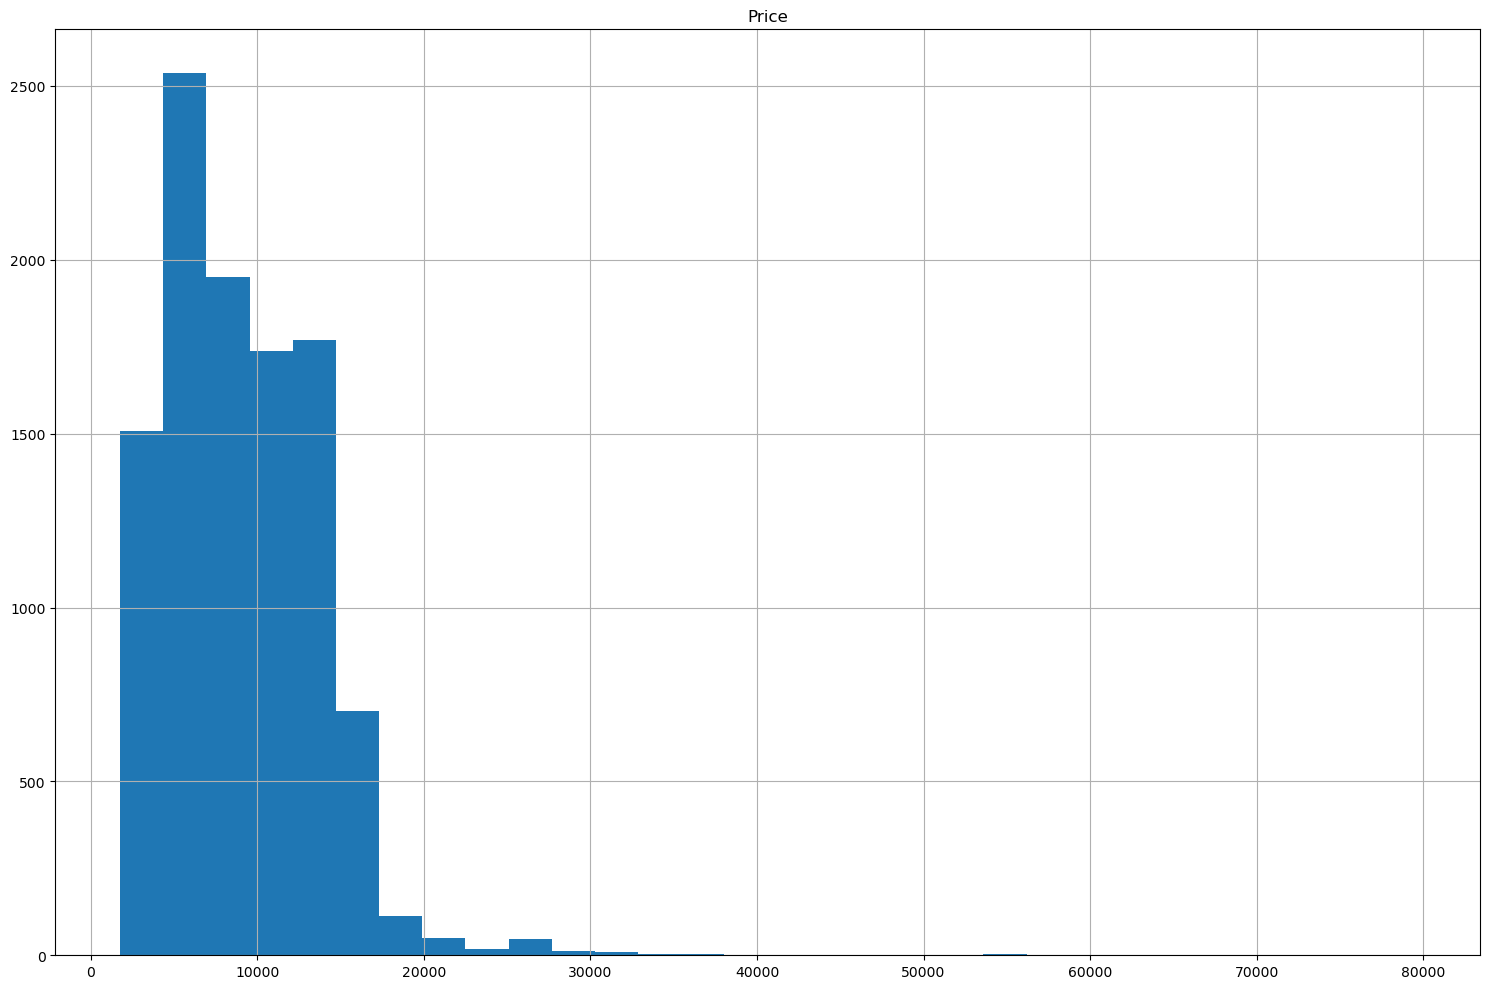

In [29]:
# Numerical Feature Distribution

df.hist(figsize=(15, 10), bins=30)

plt.tight_layout()
plt.show()

Step 11.3: Analyze categorical features

In [30]:
# Categorical Feature Distribution

categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    print(f"\nValue Counts for {col}:")
    print(df[col].value_counts().head(10))


Value Counts for Airline:
Airline
Jet Airways                          3700
IndiGo                               2043
Air India                            1695
Multiple carriers                    1196
SpiceJet                              815
Vistara                               478
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Name: count, dtype: int64

Value Counts for Date_of_Journey:
Date_of_Journey
6/06/2019     490
18/05/2019    486
9/06/2019     485
12/06/2019    483
21/05/2019    482
9/05/2019     466
21/03/2019    412
15/05/2019    402
27/05/2019    369
27/06/2019    339
Name: count, dtype: int64

Value Counts for Source:
Source
Delhi       4346
Kolkata     2860
Banglore    2179
Mumbai       697
Chennai      381
Name: count, dtype: int64

Value Counts for Destination:
Destination
Cochin       4346
Banglore     2860
Delhi        1265
New Delhi     914
Hyd

Step 11.4: Analyze flight price distribution

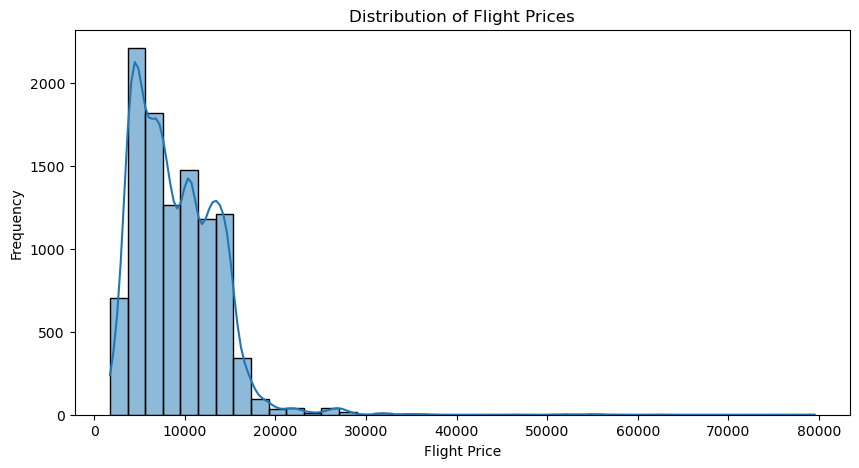

In [31]:
# Flight Price Distribution

plt.figure(figsize=(10, 5))

sns.histplot(df['Price'], bins=40, kde=True)

plt.title("Distribution of Flight Prices")
plt.xlabel("Flight Price")
plt.ylabel("Frequency")

plt.show()

Step 11.5: Check flight price statistics

In [32]:
# Flight Price Statistical Analysis

print(df['Price'].describe())

count    10463.000000
mean      9026.642454
std       4624.653227
min       1759.000000
25%       5224.000000
50%       8266.000000
75%      12343.500000
max      79512.000000
Name: Price, dtype: float64


Step 11.6: Identify outliers in flight prices

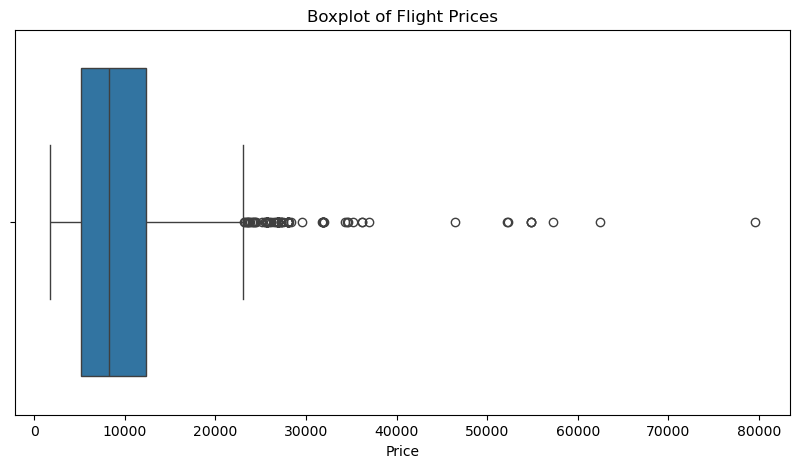

In [33]:
# Flight Price Outlier Detection

plt.figure(figsize=(10, 5))

sns.boxplot(x=df['Price'])

plt.title("Boxplot of Flight Prices")
plt.xlabel("Price")

plt.show()

Step 12: Univariate and Bivariate Analysis

Step 12.1: Flight Price by Airline

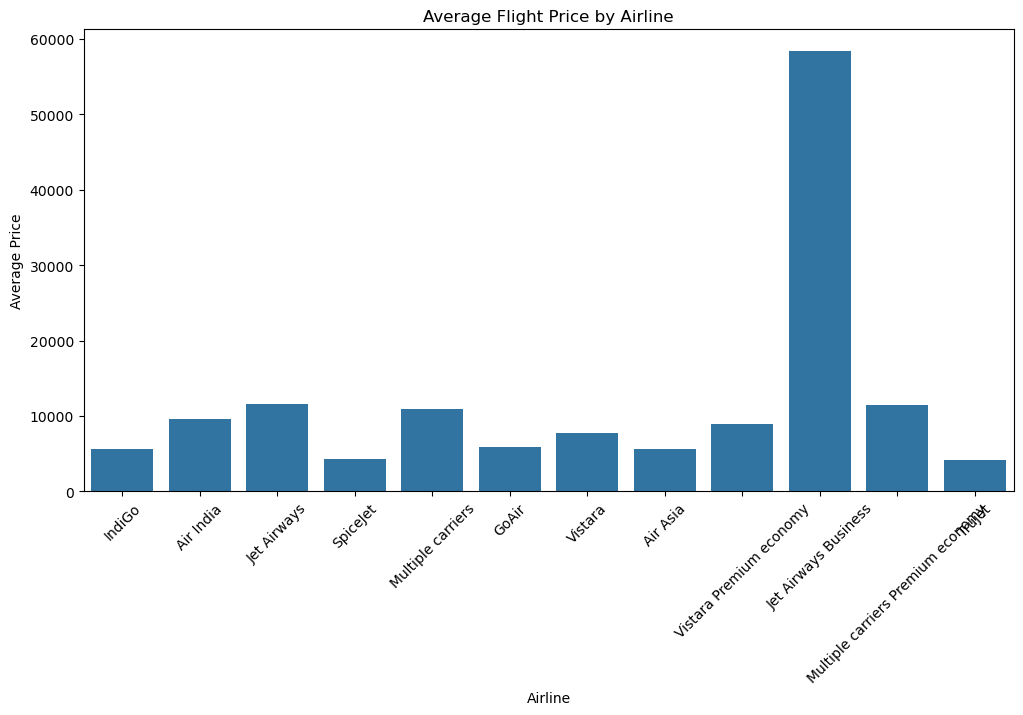

In [34]:
# Average Flight Price by Airline

plt.figure(figsize=(12, 6))

sns.barplot(data=df, x='Airline', y='Price', estimator='mean', errorbar=None)

plt.title("Average Flight Price by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Price")
plt.xticks(rotation=45)

plt.show()

Step 12.2: Flight Price by Total Stops

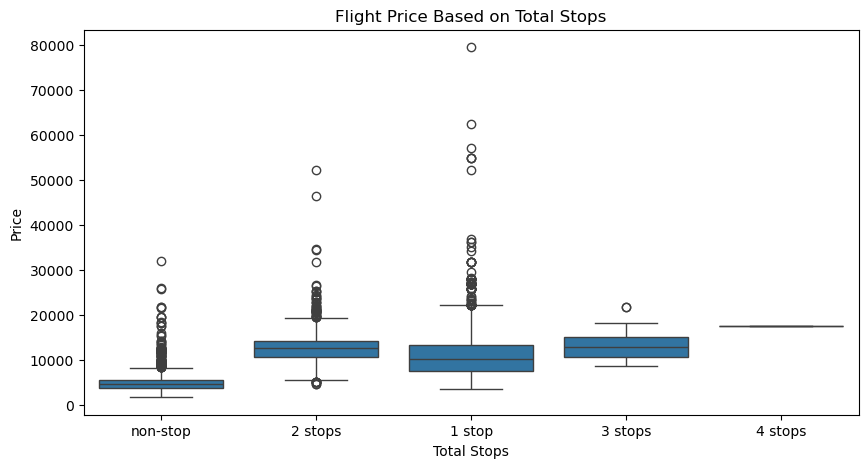

In [35]:
# Flight Price by Total Stops

plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x='Total_Stops', y='Price')

plt.title("Flight Price Based on Total Stops")
plt.xlabel("Total Stops")
plt.ylabel("Price")

plt.show()

Step 12.3: Flight Price by Source

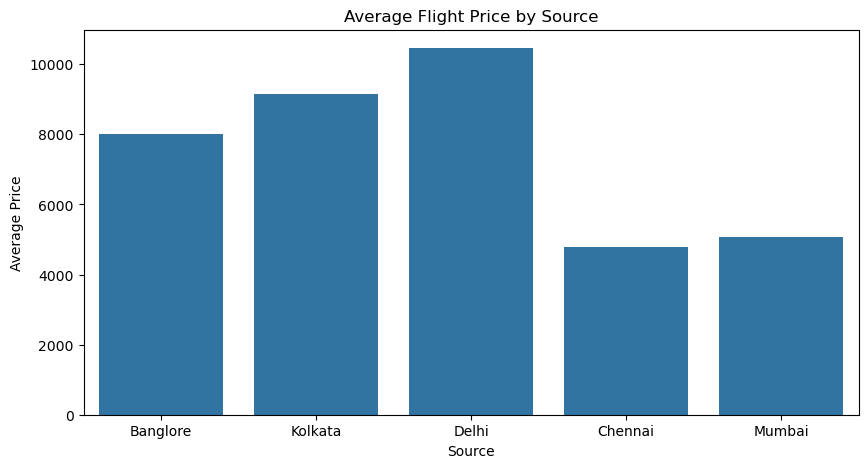

In [36]:
# Average Flight Price by Source

plt.figure(figsize=(10, 5))

sns.barplot(data=df, x='Source', y='Price', errorbar=None)

plt.title("Average Flight Price by Source")
plt.xlabel("Source")
plt.ylabel("Average Price")

plt.show()

Step 12.4: Flight Price by Destination

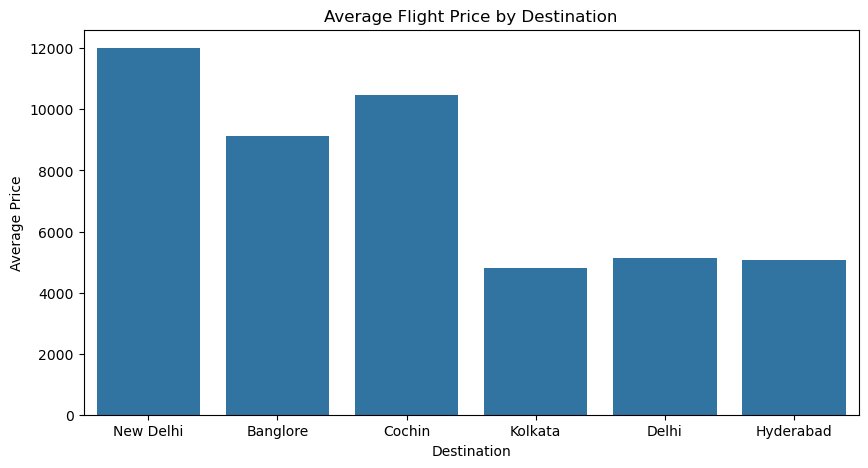

In [37]:
# Average Flight Price by Destination

plt.figure(figsize=(10, 5))

sns.barplot(data=df, x='Destination', y='Price', errorbar=None)

plt.title("Average Flight Price by Destination")
plt.xlabel("Destination")
plt.ylabel("Average Price")

plt.show()

Step 12.5: Flight Price by Departure Time

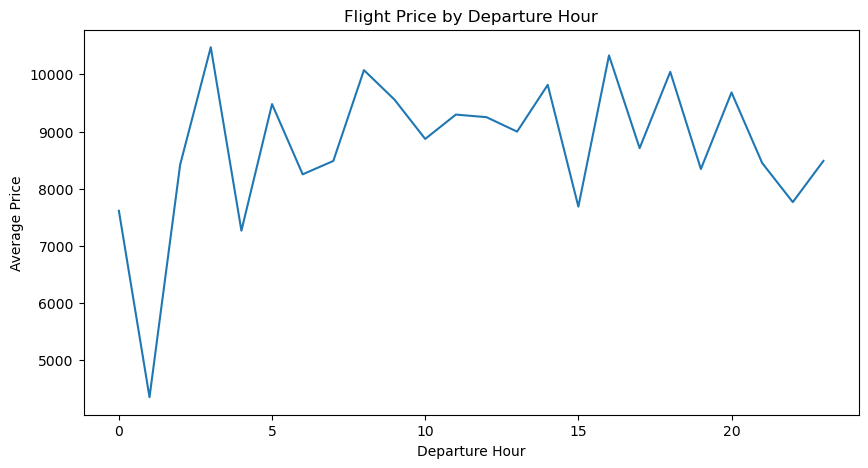

In [38]:
# Extract Departure Hour

df['Dep_Hour'] = pd.to_datetime(
    df['Dep_Time'], format='%H:%M', errors='coerce'
).dt.hour

plt.figure(figsize=(10, 5))

sns.lineplot(data=df, x='Dep_Hour', y='Price', errorbar=None)

plt.title("Flight Price by Departure Hour")
plt.xlabel("Departure Hour")
plt.ylabel("Average Price")

plt.show()

Step 12.6: Correlation Analysis

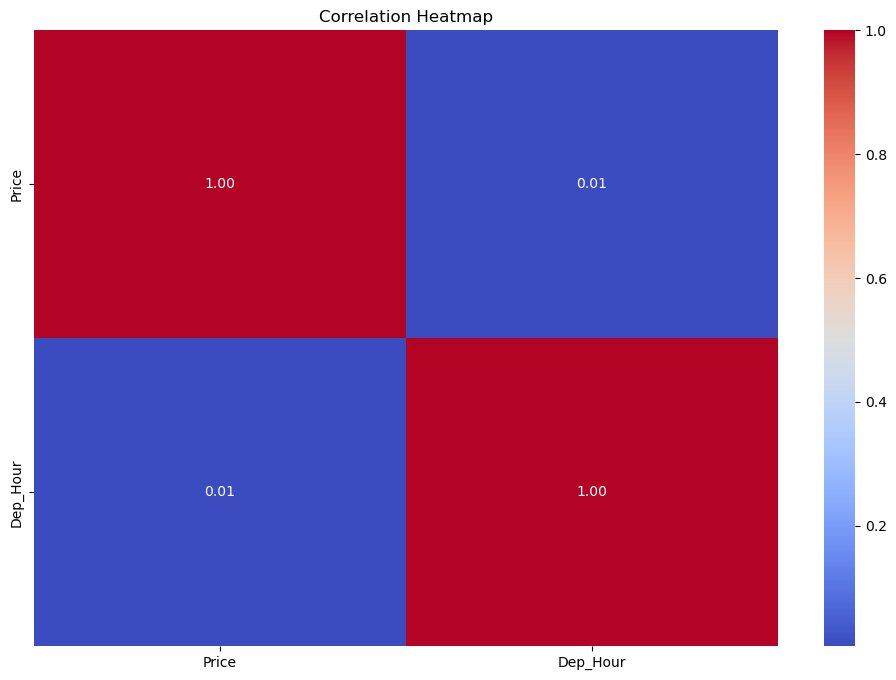

In [39]:
# Correlation Between Numerical Features

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

Step 13: Feature Engineering

Step 13.1: Extract Journey Date Features

In [40]:
# Converting Journey Date into Datetime

df['Date_of_Journey'] = pd.to_datetime(
    df['Date_of_Journey'],
    format='%d/%m/%Y'
)

# Extracting Day and Month

df['Journey_Day'] = df['Date_of_Journey'].dt.day
df['Journey_Month'] = df['Date_of_Journey'].dt.month

print("Journey date features extracted successfully!")

Journey date features extracted successfully!


Step 13.2: Extract Departure Time Features

In [41]:
# Extracting Departure Hour and Minute

df['Dep_Time'] = pd.to_datetime(
    df['Dep_Time'], format='%H:%M'
)

df['Dep_Hour'] = df['Dep_Time'].dt.hour
df['Dep_Minute'] = df['Dep_Time'].dt.minute

print("Departure time features extracted successfully!")

Departure time features extracted successfully!


Step 13.3: Extract Arrival Time Features

In [42]:
# Extracting Arrival Hour and Minute

df['Arrival_Time'] = df['Arrival_Time'].str.split().str[0]

df['Arrival_Time'] = pd.to_datetime(
    df['Arrival_Time'], format='%H:%M'
)

df['Arrival_Hour'] = df['Arrival_Time'].dt.hour
df['Arrival_Minute'] = df['Arrival_Time'].dt.minute

print("Arrival time features extracted successfully!")

Arrival time features extracted successfully!


Step 13.4: Convert Flight Duration into Minutes

In [43]:
# Converting Flight Duration into Minutes

def convert_duration(duration):
    parts = duration.split()
    hours = 0
    minutes = 0

    for part in parts:
        if 'h' in part:
            hours = int(part.replace('h', ''))
        elif 'm' in part:
            minutes = int(part.replace('m', ''))

    return hours * 60 + minutes

df['Duration_Minutes'] = df['Duration'].apply(convert_duration)

print("Flight duration converted into minutes successfully!")

Flight duration converted into minutes successfully!


Step 13.5: Check New Features

In [44]:
# Displaying Newly Created Features

df[['Journey_Day', 'Journey_Month',
    'Dep_Hour', 'Dep_Minute',
    'Arrival_Hour', 'Arrival_Minute',
    'Duration_Minutes']].head()

,Journey_Day,Journey_Month,Dep_Hour,Dep_Minute,Arrival_Hour,Arrival_Minute,Duration_Minutes
0,24,3,22,20,1,10,170
1,1,5,5,50,13,15,445
2,9,6,9,25,4,25,1140
3,12,5,18,5,23,30,325
4,1,3,16,50,21,35,285


Step 13.6: Drop Original Date and Time Columns

In [45]:
# Removing Original Date and Time Columns

df.drop(
    ['Date_of_Journey', 'Dep_Time', 'Arrival_Time', 'Duration'],
    axis=1,
    inplace=True
)

print("Original date and time columns removed successfully!")

Original date and time columns removed successfully!


Step 14: Categorical Feature Encoding

Step 14.1: Check categorical columns

In [46]:
# Identifying Categorical Columns

categorical_cols = df.select_dtypes(include='object').columns

print("Categorical Columns:")
print(categorical_cols.tolist())

Categorical Columns:
['Airline', 'Source', 'Destination', 'Route', 'Total_Stops', 'Additional_Info']


Step 14.2: Check unique values

In [47]:
# Checking Unique Values in Categorical Columns

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].nunique(), "Unique Values")


Airline:
12 Unique Values

Source:
5 Unique Values

Destination:
6 Unique Values

Route:
128 Unique Values

Total_Stops:
5 Unique Values

Additional_Info:
10 Unique Values


Step 14.3: Apply Label Encoding

In [48]:
df.head()

,Airline,Source,Destination,Route,Total_Stops,Additional_Info,Price,Dep_Hour,Journey_Day,Journey_Month,Dep_Minute,Arrival_Hour,Arrival_Minute,Duration_Minutes
0,IndiGo,Banglore,New Delhi,BLR → DEL,non-stop,No info,3897,22,24,3,20,1,10,170
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,2 stops,No info,7662,5,1,5,50,13,15,445
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,2 stops,No info,13882,9,9,6,25,4,25,1140
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,1 stop,No info,6218,18,12,5,5,23,30,325
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,1 stop,No info,13302,16,1,3,50,21,35,285


Step 14.5: Check Final Data Types

In [49]:
# Checking Final Data Types

df.dtypes

Airline             object
Source              object
Destination         object
Route               object
Total_Stops         object
Additional_Info     object
Price                int64
Dep_Hour             int32
Journey_Day          int32
Journey_Month        int32
Dep_Minute           int32
Arrival_Hour         int32
Arrival_Minute       int32
Duration_Minutes     int64
dtype: object

Step 15: Separating Independent and Dependent Variables (X and y)

Step 15.1: Separate X and y

In [50]:
# Separating Independent and Dependent Variables

X = df.drop('Price', axis=1)
y = df['Price']

print("Independent Variables (X):", X.shape)
print("Dependent Variable (y):", y.shape)

Independent Variables (X): (10463, 13)
Dependent Variable (y): (10463,)


Step 15.2: Display input features

In [51]:
X.head()

,Airline,Source,Destination,Route,Total_Stops,Additional_Info,Dep_Hour,Journey_Day,Journey_Month,Dep_Minute,Arrival_Hour,Arrival_Minute,Duration_Minutes
0,IndiGo,Banglore,New Delhi,BLR → DEL,non-stop,No info,22,24,3,20,1,10,170
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,2 stops,No info,5,1,5,50,13,15,445
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,2 stops,No info,9,9,6,25,4,25,1140
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,1 stop,No info,18,12,5,5,23,30,325
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,1 stop,No info,16,1,3,50,21,35,285


Step 15.3: Display target variable

In [52]:
y.head()

0     3897
1     7662
2    13882
3     6218
4    13302
Name: Price, dtype: int64

Step 15.4: Verify Missing Values Before Model Training

In [53]:
# Checking Missing Values Before Model Training

print("Missing Values in Independent Variables (X):")
print(X.isnull().sum())

print("\nTotal Missing Values in X:")
print(X.isnull().sum().sum())

print("\nMissing Values in Dependent Variable (y):")
print(y.isnull().sum())

print("\nTotal Missing Values in y:")
print(y.isnull().sum())

# Final Verification
if X.isnull().sum().sum() == 0 and y.isnull().sum() == 0:
    print("\nDataset is ready for Train-Test Split!")
else:
    print("\nDataset contains missing values. Further cleaning is required.")

Missing Values in Independent Variables (X):
Airline             0
Source              0
Destination         0
Route               0
Total_Stops         0
Additional_Info     0
Dep_Hour            0
Journey_Day         0
Journey_Month       0
Dep_Minute          0
Arrival_Hour        0
Arrival_Minute      0
Duration_Minutes    0
dtype: int64

Total Missing Values in X:
0

Missing Values in Dependent Variable (y):
0

Total Missing Values in y:
0

Dataset is ready for Train-Test Split!


16. Train-Test Split

16.1 – Import Train-Test Split

In [54]:
from sklearn.model_selection import train_test_split

print("Train-Test Split imported successfully!")

Train-Test Split imported successfully!


16.2 – Split the Dataset

In [55]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Dataset successfully split into training and testing sets!")

Dataset successfully split into training and testing sets!


16.3 – Check Training and Testing Shapes

In [56]:
print("Training Data Shape:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting Data Shape:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Training Data Shape:
X_train: (8370, 13)
y_train: (8370,)

Testing Data Shape:
X_test: (2093, 13)
y_test: (2093,)


16.4 – Verify Train-Test Split

In [57]:
print("Total Dataset Records:", len(X))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nTraining Data Percentage:",
      round((len(X_train) / len(X)) * 100, 2), "%")

print("Testing Data Percentage:",
      round((len(X_test) / len(X)) * 100, 2), "%")

if len(X_train) + len(X_test) == len(X):
    print("\nTrain-Test Split Verification Successful!")
else:
    print("\nTrain-Test Split Verification Failed!")

Total Dataset Records: 10463
Training Records: 8370
Testing Records: 2093

Training Data Percentage: 80.0 %
Testing Data Percentage: 20.0 %

Train-Test Split Verification Successful!


16.5 – Display Training Data

In [58]:
X_train.head()

,Airline,Source,Destination,Route,Total_Stops,Additional_Info,Dep_Hour,Journey_Day,Journey_Month,Dep_Minute,Arrival_Hour,Arrival_Minute,Duration_Minutes
6536,Air Asia,Delhi,Cochin,DEL → BLR → COK,1 stop,No info,20,9,3,10,7,10,660
6648,Jet Airways,Kolkata,Banglore,CCU → DEL → BLR,1 stop,No info,17,18,5,0,23,35,395
3445,Jet Airways,Kolkata,Banglore,CCU → BOM → BLR,1 stop,In-flight meal not included,8,18,5,25,22,35,850
8833,IndiGo,Delhi,Cochin,DEL → BOM → COK,1 stop,No info,6,15,5,40,21,0,860
3464,Jet Airways,Banglore,Delhi,BLR → DEL,non-stop,In-flight meal not included,8,6,5,20,11,20,180


16.6 – Display Testing Data

In [59]:
X_test.head()

,Airline,Source,Destination,Route,Total_Stops,Additional_Info,Dep_Hour,Journey_Day,Journey_Month,Dep_Minute,Arrival_Hour,Arrival_Minute,Duration_Minutes
7557,Air India,Kolkata,Banglore,CCU → VNS → DEL → BLR,2 stops,No info,14,6,6,30,23,15,525
8116,Air India,Kolkata,Banglore,CCU → BOM → HBX → BLR,2 stops,No info,9,1,5,25,18,20,535
3555,IndiGo,Banglore,Delhi,BLR → DEL,non-stop,No info,4,3,6,0,6,50,170
7524,Vistara,Kolkata,Banglore,CCU → DEL → BLR,1 stop,No info,20,9,6,20,20,20,1440
4762,IndiGo,Banglore,New Delhi,BLR → HYD → DEL,1 stop,No info,16,18,3,55,21,50,295


16.7 – Display Training Target Values

In [60]:
y_train.head()

6536     8327
6648    14151
3445    10844
8833     7191
3464     4544
Name: Price, dtype: int64

16.8 – Display Testing Target Values

In [61]:
y_test.head()

7557    15894
8116     8366
3555     3943
7524     8085
4762     4049
Name: Price, dtype: int64

16.9 – Section Summary

### 16.9 Train-Test Split Summary

The dataset was divided into training and testing sets using the train_test_split() function from Scikit-learn.

80% of the data was allocated for model training, while the remaining 20% was used for model testing.

The random_state parameter was set to 42 to ensure reproducibility of the results. This split helps evaluate how well the trained Machine Learning models perform on unseen data.

Step 17 – Error Fix: Convert Categorical Data into Numeric Data

17.1 – Identify Remaining Text Columns

In [66]:
# Identify columns containing text data

categorical_columns = X.select_dtypes(include=['object']).columns

print("Categorical Columns Remaining:")
print(list(categorical_columns))

print("\nTotal Categorical Columns:", len(categorical_columns))

Categorical Columns Remaining:
['Airline', 'Source', 'Destination', 'Route', 'Total_Stops', 'Additional_Info']

Total Categorical Columns: 6


17.2 – Check the Data Types

In [67]:
# Check data types of all independent variables

print("Independent Variables Data Types:\n")
print(X.dtypes)

Independent Variables Data Types:

Airline             object
Source              object
Destination         object
Route               object
Total_Stops         object
Additional_Info     object
Dep_Hour             int32
Journey_Day          int32
Journey_Month        int32
Dep_Minute           int32
Arrival_Hour         int32
Arrival_Minute       int32
Duration_Minutes     int64
dtype: object


17.3 – Encode Remaining Categorical Columns

In [68]:
from sklearn.preprocessing import LabelEncoder

# Encode remaining categorical columns

label_encoders = {}

for col in categorical_columns:

    le = LabelEncoder()

    X[col] = le.fit_transform(X[col].astype(str))

    label_encoders[col] = le

print("Remaining categorical columns encoded successfully!")

Remaining categorical columns encoded successfully!


17.4 – Verify the Converted Data

In [69]:
print("Updated Data Types:\n")
print(X.dtypes)

print("\nRemaining Text Columns:")
print(list(X.select_dtypes(include=['object']).columns))

Updated Data Types:

Airline             int64
Source              int64
Destination         int64
Route               int64
Total_Stops         int64
Additional_Info     int64
Dep_Hour            int32
Journey_Day         int32
Journey_Month       int32
Dep_Minute          int32
Arrival_Hour        int32
Arrival_Minute      int32
Duration_Minutes    int64
dtype: object

Remaining Text Columns:
[]


17.5 – Verify Missing Values

In [70]:
print("Missing Values in X:", X.isnull().sum().sum())
print("Missing Values in y:", y.isnull().sum())

print("\nAll Independent Variables Numeric:",
      X.select_dtypes(include=['object']).empty)

Missing Values in X: 0
Missing Values in y: 0

All Independent Variables Numeric: True


17.6 – Perform Train-Test Split Again

In [71]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train-Test Split Completed Successfully!")

print("\nX_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

Train-Test Split Completed Successfully!

X_train Shape: (8370, 13)
X_test Shape: (2093, 13)
y_train Shape: (8370,)
y_test Shape: (2093,)


17. Model Building and Training

17.7 – Import Machine Learning Models

In [72]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor
)

print("Machine Learning models imported successfully!")

Machine Learning models imported successfully!


17.8 – Initialize All Five Models

In [73]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

print("All five models initialized successfully!")

All five models initialized successfully!


17.9 – Train All Machine Learning Models

In [74]:
trained_models = {}

for model_name, model in models.items():

    print(f"Training {model_name}...")

    model.fit(X_train, y_train)

    trained_models[model_name] = model

    print(f"{model_name} trained successfully!\n")

print("All five Machine Learning models trained successfully!")

Training Linear Regression...
Linear Regression trained successfully!

Training Decision Tree...
Decision Tree trained successfully!

Training Random Forest...
Random Forest trained successfully!

Training Gradient Boosting...
Gradient Boosting trained successfully!

Training Extra Trees...
Extra Trees trained successfully!

All five Machine Learning models trained successfully!


17.10 – Verify Trained Models

In [75]:
print("Trained Models Verification:\n")

for model_name, model in trained_models.items():

    print(f"{model_name}: {type(model).__name__}")

print("\nTotal Models Trained:", len(trained_models))

Trained Models Verification:

Linear Regression: LinearRegression
Decision Tree: DecisionTreeRegressor
Random Forest: RandomForestRegressor
Gradient Boosting: GradientBoostingRegressor
Extra Trees: ExtraTreesRegressor

Total Models Trained: 5


17.11 – Generate Predictions

In [76]:
predictions = {}

for model_name, model in trained_models.items():

    y_pred = model.predict(X_test)

    predictions[model_name] = y_pred

    print(f"{model_name} predictions generated successfully!")

print("\nPredictions generated for all five models!")

Linear Regression predictions generated successfully!
Decision Tree predictions generated successfully!
Random Forest predictions generated successfully!
Gradient Boosting predictions generated successfully!
Extra Trees predictions generated successfully!

Predictions generated for all five models!


17.12 – Compare Actual and Predicted Prices

In [77]:
prediction_results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Linear Regression": predictions["Linear Regression"],
    "Decision Tree": predictions["Decision Tree"],
    "Random Forest": predictions["Random Forest"],
    "Gradient Boosting": predictions["Gradient Boosting"],
    "Extra Trees": predictions["Extra Trees"]
})

prediction_results.head(10)

,Actual Price,Linear Regression,Decision Tree,Random Forest,Gradient Boosting,Extra Trees
0,15894,8543.784884,14214.0,13258.019,11132.827140,14166.59
1,8366,9335.621625,8366.0,10380.720,11439.349073,10138.28
2,3943,6043.427202,3943.0,3939.540,4622.955654,3943.00
3,8085,12656.495207,8085.0,8600.600,9315.420322,8303.39
4,4049,11736.271119,4340.0,6032.120,6591.525679,5681.34
5,4668,6762.521199,4668.0,4812.730,5244.630274,4693.20
6,11411,9430.291115,11411.0,12502.320,11277.387461,12355.34
7,7594,9503.239412,8586.0,7879.270,10249.220281,7320.29
8,7934,10529.012219,6377.0,7186.220,8325.035292,7057.35
9,12692,12203.222505,12692.0,13205.980,13349.877076,13153.08


17.13 – Model Training Summary

### 17.13 Model Building and Training Summary

Five Machine Learning regression algorithms were selected and trained using the training dataset.

The selected algorithms include Linear Regression, Decision Tree Regressor, Random Forest Regressor, Gradient Boosting Regressor, and Extra Trees Regressor.

After training, predictions were generated using the testing dataset. The actual and predicted flight ticket prices were stored for further evaluation.

These models will be evaluated using regression performance metrics to identify the best-performing model for flight price prediction.

18. Model Evaluation

18.1 – Import Evaluation Metrics

In [78]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

print("Model evaluation metrics imported successfully!")

Model evaluation metrics imported successfully!


18.2 – Calculate MAE, MSE, RMSE and R² Score

In [79]:
evaluation_results = []

for model_name, y_pred in predictions.items():

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    evaluation_results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

print("All models evaluated successfully!")

All models evaluated successfully!


18.3 – Create Model Evaluation DataFrame

In [80]:
evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,2475.389925,1.200745e+07,3465.177330,0.424508
1,Decision Tree,798.783883,5.990664e+06,2447.583217,0.712880
2,Random Forest,641.618563,2.173951e+06,1474.432462,0.895807
3,Gradient Boosting,1260.084657,3.815075e+06,1953.221670,0.817152
4,Extra Trees,614.414094,2.209346e+06,1486.386859,0.894111


18.4 – Sort Models Based on R² Score

In [81]:
evaluation_df_sorted = evaluation_df.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

evaluation_df_sorted

,Model,MAE,MSE,RMSE,R2 Score
0,Random Forest,641.618563,2.173951e+06,1474.432462,0.895807
1,Extra Trees,614.414094,2.209346e+06,1486.386859,0.894111
2,Gradient Boosting,1260.084657,3.815075e+06,1953.221670,0.817152
3,Decision Tree,798.783883,5.990664e+06,2447.583217,0.712880
4,Linear Regression,2475.389925,1.200745e+07,3465.177330,0.424508


18.5 – Identify the Best Model Based on R² Score

In [82]:
best_model_name = evaluation_df_sorted.loc[0, "Model"]

best_r2_score = evaluation_df_sorted.loc[0, "R2 Score"]

print("Best Performing Model:", best_model_name)

print("Best R2 Score:", round(best_r2_score, 4))

Best Performing Model: Random Forest
Best R2 Score: 0.8958


18.6 – Visualize Model Performance Using MAE

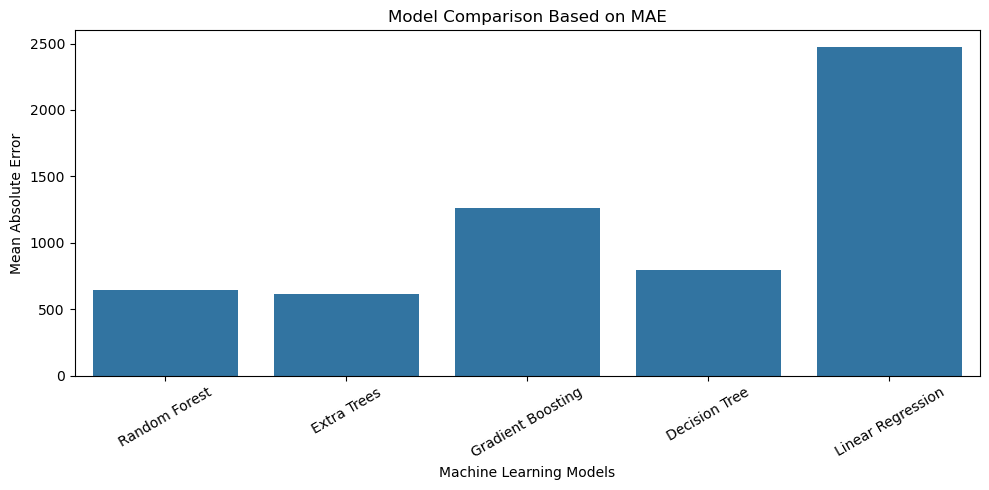

In [83]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=evaluation_df_sorted,
    x="Model",
    y="MAE"
)

plt.title("Model Comparison Based on MAE")
plt.xlabel("Machine Learning Models")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

18.7 – Visualize Model Performance Using RMSE

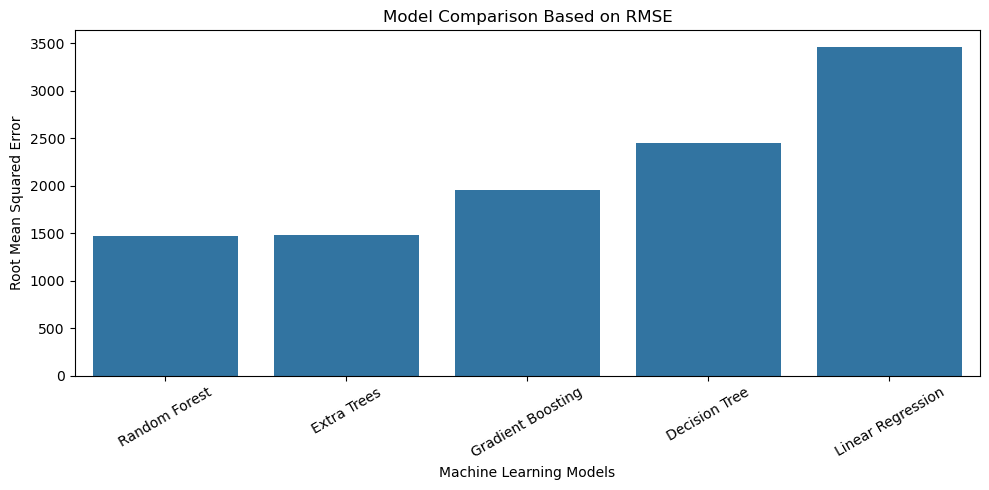

In [84]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=evaluation_df_sorted,
    x="Model",
    y="RMSE"
)

plt.title("Model Comparison Based on RMSE")
plt.xlabel("Machine Learning Models")
plt.ylabel("Root Mean Squared Error")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

18.8 – Visualize Model Performance Using R² Score

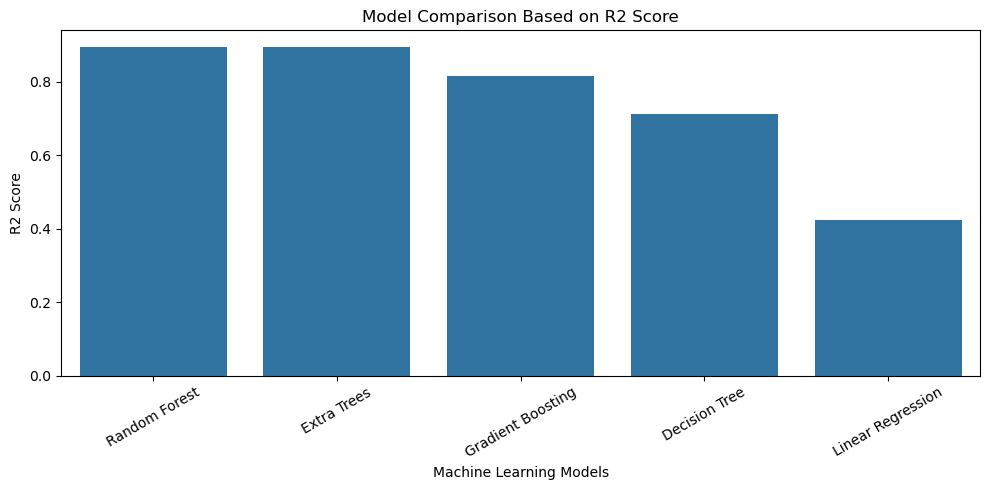

In [85]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=evaluation_df_sorted,
    x="Model",
    y="R2 Score"
)

plt.title("Model Comparison Based on R2 Score")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

18.9 – Model Evaluation Summary

### 18.9 Model Evaluation Summary

The performance of five Machine Learning regression models was evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R2 Score.

MAE, MSE, and RMSE were used to measure prediction errors, where lower values indicate better performance.

The R2 Score was used to measure how effectively each model explains the variation in flight ticket prices, where a higher value generally indicates better performance.

The evaluation results were organized into a comparison table and visualized using bar charts to identify the most promising model.

19. Model Comparison and Best Model Selection

19.1 – Display Final Model Comparison

In [86]:
evaluation_df_sorted

,Model,MAE,MSE,RMSE,R2 Score
0,Random Forest,641.618563,2.173951e+06,1474.432462,0.895807
1,Extra Trees,614.414094,2.209346e+06,1486.386859,0.894111
2,Gradient Boosting,1260.084657,3.815075e+06,1953.221670,0.817152
3,Decision Tree,798.783883,5.990664e+06,2447.583217,0.712880
4,Linear Regression,2475.389925,1.200745e+07,3465.177330,0.424508


19.2 – Identify the Best Model Based on Evaluation Metrics

In [87]:
best_model_row = evaluation_df_sorted.loc[
    evaluation_df_sorted["RMSE"].idxmin()
]

best_model_name = best_model_row["Model"]

print("Best Model:", best_model_name)
print("MAE:", round(best_model_row["MAE"], 2))
print("MSE:", round(best_model_row["MSE"], 2))
print("RMSE:", round(best_model_row["RMSE"], 2))
print("R2 Score:", round(best_model_row["R2 Score"], 4))

Best Model: Random Forest
MAE: 641.62
MSE: 2173951.09
RMSE: 1474.43
R2 Score: 0.8958


19.3 – Select the Best Trained Model

In [88]:
best_model = trained_models[best_model_name]

print("Selected Model:", best_model_name)
print("Best model selected successfully!")

Selected Model: Random Forest
Best model selected successfully!


19.4 – Generate Predictions Using the Best Model

In [89]:
best_predictions = best_model.predict(X_test)

print("Predictions generated using the best model!")

Predictions generated using the best model!


19.5 – Compare Actual and Predicted Prices

In [90]:
best_model_results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": best_predictions
})

best_model_results["Prediction Error"] = (
    best_model_results["Actual Price"] -
    best_model_results["Predicted Price"]
)

best_model_results.head(10)

,Actual Price,Predicted Price,Prediction Error
0,15894,13258.019,2635.981
1,8366,10380.720,-2014.720
2,3943,3939.540,3.460
3,8085,8600.600,-515.600
4,4049,6032.120,-1983.120
5,4668,4812.730,-144.730
6,11411,12502.320,-1091.320
7,7594,7879.270,-285.270
8,7934,7186.220,747.780
9,12692,13205.980,-513.980


19.6 – Visualize Actual vs Predicted Prices

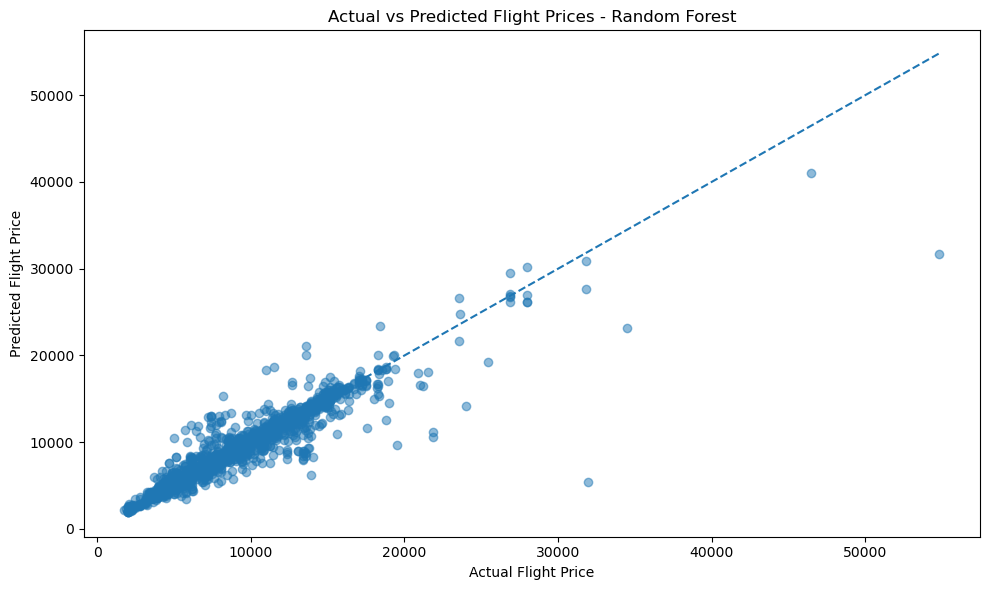

In [91]:
plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.5
)

min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title(f"Actual vs Predicted Flight Prices - {best_model_name}")
plt.xlabel("Actual Flight Price")
plt.ylabel("Predicted Flight Price")

plt.tight_layout()
plt.show()

19.7 – Visualize Prediction Errors

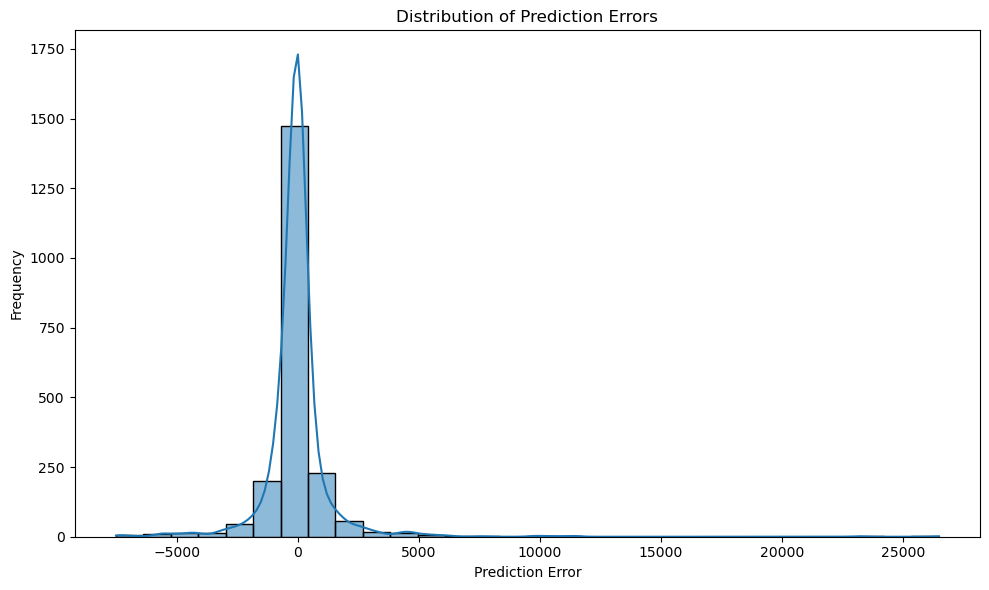

In [92]:
plt.figure(figsize=(10, 6))

sns.histplot(
    best_model_results["Prediction Error"],
    bins=30,
    kde=True
)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

19.8 – Save the Best Machine Learning Model

In [93]:
import joblib

model_filename = "Best_Flight_Price_Prediction_Model.pkl"

joblib.dump(best_model, model_filename)

print("Best model saved successfully!")
print("Saved File:", model_filename)

Best model saved successfully!
Saved File: Best_Flight_Price_Prediction_Model.pkl


19.9 – Load and Verify the Saved Model

In [94]:
loaded_model = joblib.load(model_filename)

print("Saved model loaded successfully!")

loaded_predictions = loaded_model.predict(X_test)

print("Model prediction verification completed!")

print("\nFirst 5 Predictions:")
print(loaded_predictions[:5])

Saved model loaded successfully!
Model prediction verification completed!

First 5 Predictions:
[13258.019 10380.72   3939.54   8600.6    6032.12 ]


19.10 – Verify Model Saving Performance

In [95]:
if np.allclose(best_predictions, loaded_predictions):

    print("Model Saving Verification Successful!")
    print("Original and Loaded Model Predictions Match.")

else:

    print("Model Saving Verification Failed!")

Model Saving Verification Successful!
Original and Loaded Model Predictions Match.


19.11 – Model Comparison and Selection Summary`

### 19.11 Model Comparison and Best Model Selection Summary

The performance of all five Machine Learning models was compared using MAE, MSE, RMSE, and R2 Score.

The model with the lowest RMSE was selected as the initial best-performing model after considering its prediction error and other evaluation metrics.

Actual and predicted flight ticket prices were compared using a scatter plot to understand the prediction performance.

The prediction error distribution was also visualized to analyze the differences between actual and predicted prices.

Finally, the selected model was saved as a Pickle file using Joblib. The saved model was loaded again and tested to verify that it generated consistent predictions.

20. Challenges Faced and Solutions

20.1 – Challenges Faced

### 20.1 Challenges Faced

During the Flight Price Prediction project, several challenges were encountered while preparing the dataset and developing Machine Learning models.

1. Missing Values:
Some records contained missing values, which required proper identification and treatment.

2. Duplicate Records:
Duplicate entries were identified and removed to improve data quality.

3. Data Cleaning:
The dataset contained different data types and categorical information that required preprocessing.

4. Date and Time Conversion:
Journey dates, departure times, arrival times, and flight durations were converted into meaningful numerical features.

5. Categorical Data Encoding:
Categorical variables such as Airline, Source, Destination, and Total Stops needed to be converted into numerical values for Machine Learning algorithms.

6. Model Selection:
Multiple regression algorithms were tested to identify a suitable model for predicting flight ticket prices.

7. Prediction Accuracy:
Different models produced different prediction errors, making model evaluation and comparison necessary.

20.2 – Solutions Implemented

### 20.2 Solutions Implemented

The following techniques were implemented to overcome the challenges encountered during the project.

1. Missing Value Treatment:
Missing values were identified using Pandas and handled using appropriate statistical methods.

2. Duplicate Removal:
Duplicate records were removed using the drop_duplicates() method.

3. Data Preprocessing:
The dataset was inspected, cleaned, and prepared for Machine Learning model development.

4. Feature Engineering:
Journey day, journey month, departure hour, arrival hour, and flight duration in minutes were extracted to create useful numerical features.

5. Label Encoding:
Label Encoding was applied to convert categorical variables into numerical representations.

6. Model Training:
Five regression algorithms were trained and tested using the training and testing datasets.

7. Model Evaluation:
MAE, MSE, RMSE, and R2 Score were used to evaluate and compare model performance.

8. Model Saving:
The selected trained model was saved using Joblib for future use.

20.3 – Challenges and Solutions Summary

### 20.3 Challenges and Solutions Summary

The challenges encountered during data preprocessing and model development were addressed using data cleaning, feature engineering, categorical encoding, and regression evaluation techniques.

These approaches helped prepare the flight fare dataset for Machine Learning and enabled comparison of multiple regression algorithms to identify a suitable model for flight price prediction.

21. Project Conclusion

21.1 – Final Project Conclusion

# 21. Project Conclusion

The Flight Price Prediction project was developed to predict flight ticket prices using Machine Learning techniques.

The dataset was analyzed and preprocessed by handling missing values, removing duplicate records, converting date and time information, and encoding categorical features.

Exploratory Data Analysis was performed to understand flight price distributions and relationships between ticket prices and different travel-related attributes.

Feature engineering techniques were applied to extract useful information from journey dates, departure times, arrival times, and flight durations.

Five Machine Learning regression algorithms were implemented: Linear Regression, Decision Tree Regressor, Random Forest Regressor, Gradient Boosting Regressor, and Extra Trees Regressor.

The models were evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R2 Score. Their performance was compared to identify the most suitable model.

The selected model was saved using Joblib for future use.

Overall, this project provided practical experience in data analysis, data preprocessing, feature engineering, regression modelling, model evaluation, and Machine Learning model development.

21.2 – Final Project Completion Verification

In [96]:
print("FLIGHT PRICE PREDICTION PROJECT")
print("--------------------------------")

print("Dataset Shape:", df.shape)

print("Total Features:", X.shape[1])

print("Training Records:", X_train.shape[0])

print("Testing Records:", X_test.shape[0])

print("Total Models Trained:", len(trained_models))

print("Selected Model:", best_model_name)

print("Model File:", model_filename)

print("--------------------------------")
print("PROJECT WORKFLOW COMPLETED!")

FLIGHT PRICE PREDICTION PROJECT
--------------------------------
Dataset Shape: (10463, 14)
Total Features: 13
Training Records: 8370
Testing Records: 2093
Total Models Trained: 5
Selected Model: Random Forest
Model File: Best_Flight_Price_Prediction_Model.pkl
--------------------------------
PROJECT WORKFLOW COMPLETED!
